# **Healthcare Insurance Cost Analysis — Data Cleaning & EDA**

## Objectives

* Understand the healthcare insurance dataset and its variables.
* Prepare the raw data for analysis through a clear ETL process.
* Check data quality, including data types, missing values, duplicates and potential outliers.
* Perform appropriate data transformations where required.
* Conduct exploratory data analysis (EDA) to understand patterns and relationships in insurance charges.
* Generate descriptive statistics and visualisations that support the project's research questions.

## Inputs

* Raw healthcare insurance dataset: `data/insurance.csv`
* Project business problem, research questions and hypotheses.
* Relevant findings and useful analytical work from Assessment 1, used as a reference for developing this Assessment 2 analysis.

## Outputs

* A validated and cleaned dataset suitable for statistical analysis and machine learning.
* Documented data-cleaning and transformation steps.
* Descriptive statistics describing the main variables.
* Exploratory visualisations showing important patterns and relationships in the data.
* Initial findings that will inform the statistical analysis and hypothesis testing in the next stage.

## Initialising the Project

This notebook is part of the Healthcare Insurance Cost Analysis project.

The project uses Python and the provided healthcare insurance dataset to
prepare, explore and analyse insurance charges.

The project environment uses Python 3.12.8 and the required Python libraries
for data analysis and visualisation.

The raw dataset is stored in the project's `data` directory and is retained
as the original source data.

## Changing the Working Directory

As this notebook is stored in the `notebooks` directory, the working
directory is changed to the main project directory so that project files can
be accessed using relative paths.

In [1]:
import os

# Set the working directory to the main project folder
project_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
os.chdir(project_dir)

# Check the working directory
print(os.getcwd())

d:\Code\Assessment 2\code-institute_Assessment_2_Healthcare_Insurance_ML\code-institute-_-Assessment-2-Healthcare-Insurance-ML


## Section 1 — Import Tools

The following Python libraries are used in this notebook for data loading,
cleaning, transformation, exploratory data analysis and visualisation.

In [10]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Extract & Load Dataset

### 2.1 Load the Raw Dataset

The raw healthcare insurance dataset is stored in the project's `data` directory.

The original raw dataset is retained unchanged and is used as the source for the ETL process. The dataset is loaded into a pandas DataFrame for inspection and subsequent transformation.

In [12]:
# Load the raw dataset
raw_data = pd.read_csv("data/insurance.csv")

# Display the first five rows
raw_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### 2.2 Initial Dataset Inspection

The first inspection checks the structure, dimensions, column names, data types and basic information of the raw dataset before any transformation is performed.

In [13]:
# Inspect the structure of the raw dataset

print("Dataset shape:", raw_data.shape)
print("\nColumn names:")
print(raw_data.columns.tolist())

print("\nData types:")
print(raw_data.dtypes)

print("\nDataset information:")
raw_data.info()

Dataset shape: (1338, 7)

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### 2.3 Data Quality Checks

The raw dataset is checked for missing values and duplicate records before any transformations are applied. These checks help identify potential data-quality issues that may affect subsequent analysis.

In [14]:
# Check for missing values
print("Missing values:")
print(raw_data.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:")
print(raw_data.duplicated().sum())

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of duplicate rows:
1


### 2.4 Investigate Duplicate Records

The initial quality check identified one duplicate row. The duplicate record is inspected before deciding whether it should be removed during the transformation stage.

In [15]:
# Display duplicate records
duplicates = raw_data[raw_data.duplicated(keep=False)]

duplicates

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


### 2.5 Remove Duplicate Records

The dataset contains one exact duplicate record. As the duplicate does not provide additional information, one copy is removed from the analytical dataset.

The original raw dataset is retained unchanged, and the duplicate removal is applied only to the working dataset.

In [16]:
# Create a working copy of the raw dataset
data = raw_data.copy()

# Remove duplicate records
data = data.drop_duplicates()

# Check the number of remaining duplicate rows
print("Duplicate rows after removal:", data.duplicated().sum())
print("Dataset shape after duplicate removal:", data.shape)

Duplicate rows after removal: 0
Dataset shape after duplicate removal: (1337, 7)


In [17]:
# Review data types
print(data.dtypes)

# Display unique values for categorical variables
categorical_columns = ["sex", "smoker", "region"]

for column in categorical_columns:
    print(f"\n{column}:")
    print(data[column].unique())

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

sex:
['female' 'male']

smoker:
['yes' 'no']

region:
['southwest' 'southeast' 'northwest' 'northeast']


### 2.7 Numerical Variables and Outlier Inspection

The numerical variables are reviewed using descriptive statistics to identify their ranges and potential extreme values. Outliers are not removed automatically because extreme insurance charges may represent genuine customer observations and could be important for the analysis.

In [18]:
# Summary statistics for numerical variables
data.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


### 2.8 Outlier Check Using the IQR Method

Potential outliers in the numerical variables are identified using the Interquartile Range (IQR) method.

The IQR is calculated as the difference between the third quartile (Q3) and first quartile (Q1). Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

Potential outliers will be investigated rather than automatically removed, because extreme values may represent genuine insurance customers and may contain useful information for the analysis.

In [19]:
# Identify potential outliers using the IQR method

numerical_columns = ["age", "bmi", "children", "charges"]

for column in numerical_columns:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\n{column}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")


age
IQR: 24.00
Lower bound: -9.00
Upper bound: 87.00
Potential outliers: 0

bmi
IQR: 8.41
Lower bound: 13.67
Upper bound: 47.32
Potential outliers: 9

children
IQR: 2.00
Lower bound: -3.00
Upper bound: 5.00
Potential outliers: 0

charges
IQR: 11911.37
Lower bound: -13120.72
Upper bound: 34524.78
Potential outliers: 139


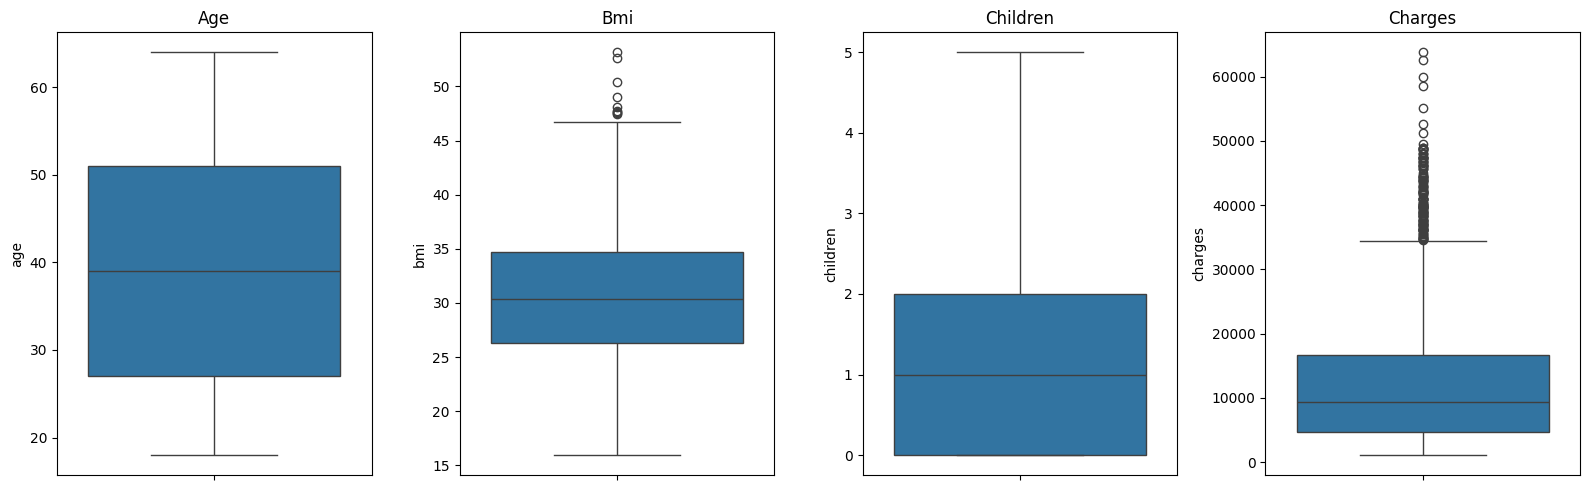

In [22]:

# Box plots for numerical variables
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(y=data[column], ax=ax)
    ax.set_title(column.capitalize())

plt.tight_layout()
plt.show()

### 2.10 Outlier Treatment Decision

The IQR analysis and box plots identified potential upper-tail outliers in BMI and insurance charges. No obvious outliers were identified for age or number of children.

The potential outliers in BMI and charges have been retained because they may represent genuine observations rather than data-entry errors. In particular, high insurance charges are relevant to the business objective of understanding healthcare insurance costs.

Therefore, no observations are removed solely because they are classified as statistical outliers. The potential influence of extreme values will be considered during the subsequent exploratory and statistical analysis.

### 2.11 Categorical Data Consistency

The categorical variables are checked for unexpected, inconsistent, or incorrectly entered values.

This check ensures that categories such as sex, smoking status and region can be used reliably in subsequent analysis and modelling.

In [23]:
# Check the frequency of each categorical value

categorical_columns = ["sex", "smoker", "region"]

for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(data[column].value_counts())


SEX
sex
male      675
female    662
Name: count, dtype: int64

SMOKER
smoker
no     1063
yes     274
Name: count, dtype: int64

REGION
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


### 2.12 Create BMI Categories

A BMI category is created as an additional analytical feature. This provides a categorical representation of BMI that can be used to compare insurance charges across different BMI groups.

The original `bmi` variable is retained so that the continuous BMI measurement remains available for numerical analysis.

In [24]:
# Create BMI category

data["bmi_category"] = pd.cut(
    data["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
)

# Check the new feature
print(data["bmi_category"].value_counts())

data[["bmi", "bmi_category"]].head(10)

bmi_category
Obese          704
Overweight     386
Normal         226
Underweight     21
Name: count, dtype: int64


,bmi,bmi_category
0,27.900,Overweight
1,33.770,Obese
2,33.000,Obese
3,22.705,Normal
4,28.880,Overweight
5,25.740,Overweight
6,33.440,Obese
7,27.740,Overweight
8,29.830,Overweight
9,25.840,Overweight


### 2.13 Validate the Transformed Dataset

The transformed dataset is validated to confirm that the duplicate has been removed, no missing values have been introduced, the BMI categories have been created correctly, and the expected number of records and variables is maintained.

In [25]:
# Validate the transformed dataset

print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

print("\nBMI categories:")
print(data["bmi_category"].value_counts(dropna=False))

Dataset shape: (1337, 8)

Missing values:
age             0
sex             0
bmi             0
children        0
smoker          0
region          0
charges         0
bmi_category    0
dtype: int64

Duplicate rows:
0

BMI categories:
bmi_category
Obese          704
Overweight     386
Normal         226
Underweight     21
Name: count, dtype: int64


### 2.14 Load the Clean Analytical Dataset

The validated transformed dataset is saved as a separate CSV file in the `data` directory.

The original `insurance.csv` file is retained unchanged as the raw source dataset. The cleaned dataset is used for subsequent exploratory analysis, statistical analysis and machine learning.

In [26]:
# Save the validated analytical dataset

clean_data_path = "data/cleaned_insurance.csv"

data.to_csv(clean_data_path, index=False)

print(f"Clean analytical dataset saved to: {clean_data_path}")

Clean analytical dataset saved to: data/cleaned_insurance.csv


In [27]:
# Reload the saved analytical dataset to verify the output

clean_data = pd.read_csv(clean_data_path)

print("Loaded dataset shape:", clean_data.shape)
clean_data.head()

Loaded dataset shape: (1337, 8)


,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obese
2,28,male,33.000,3,no,southeast,4449.46200,Obese
3,33,male,22.705,0,no,northwest,21984.47061,Normal
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


## 2.15 ETL Summary

The dataset was processed using an Extract, Transform, Validate and Load workflow.

### Extract
- The original `insurance.csv` file was loaded into a pandas DataFrame.
- The raw dataset was retained unchanged.

### Transform
- The dataset was inspected for missing values and duplicates.
- One exact duplicate record was removed from the working dataset.
- Data types and categorical values were checked for consistency.
- Potential outliers were investigated using descriptive statistics, the IQR method and box plots.
- Potential outliers were retained because they were not identified as data-entry errors and may represent genuine insurance observations.
- A new `bmi_category` feature was created while retaining the original continuous `bmi` variable.

### Validate
- The transformed dataset was checked for missing values and duplicates.
- The expected dataset structure was confirmed.

### Load
- The validated analytical dataset was saved as `data/cleaned_insurance.csv`.
- The original raw dataset remains unchanged.

In [28]:
# Final ETL verification

print("Final dataset shape:", clean_data.shape)
print("Missing values:", clean_data.isnull().sum().sum())
print("Duplicate rows:", clean_data.duplicated().sum())
print("Columns:", clean_data.columns.tolist())

Final dataset shape: (1337, 8)
Missing values: 0
Duplicate rows: 0
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges', 'bmi_category']


# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is used to understand the structure, distributions and relationships within the cleaned healthcare insurance dataset.

The analysis will use descriptive statistics and visualisations to identify patterns that are relevant to the business problem and research questions.

The EDA will investigate:

- The distribution of insurance charges
- The relationship between age and charges
- The relationship between BMI and charges
- Differences in charges between smokers and non-smokers
- Differences in charges between males and females
- The relationship between number of children and charges
- Differences in charges between geographic regions
- The combined relationship between BMI, smoking status and charges
- Correlations between numerical variables

## 3.1 Descriptive Statistics

Descriptive statistics are used to summarise the numerical variables in the cleaned dataset.

The summary statistics provide information about the central tendency, spread and range of the numerical variables before examining their distributions visually.

In [30]:
data.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


## 3.2 Distribution of Insurance Charges

The distribution of insurance charges is examined to understand the central tendency, spread and shape of the target variable.

A histogram is used to visualise the frequency distribution of charges, while a box plot provides an additional view of the spread and potential extreme values.

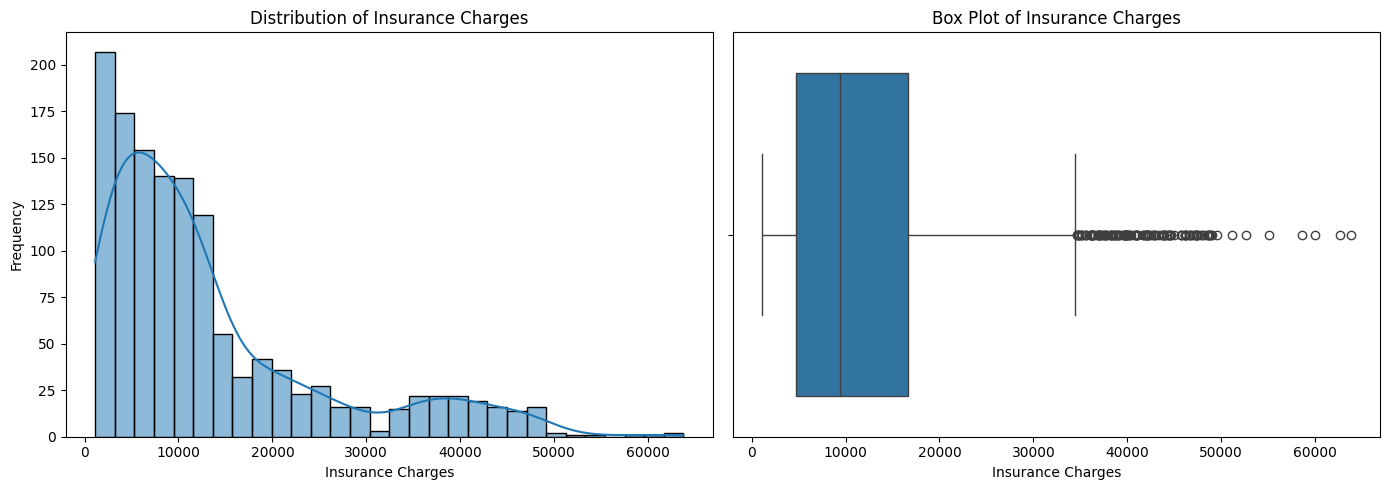

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(data["charges"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Insurance Charges")
axes[0].set_xlabel("Insurance Charges")
axes[0].set_ylabel("Frequency")

# Box plot
sns.boxplot(x=data["charges"], ax=axes[1])
axes[1].set_title("Box Plot of Insurance Charges")
axes[1].set_xlabel("Insurance Charges")

plt.tight_layout()
plt.show()

### EDA Note — Distribution of Insurance Charges

The distribution of insurance charges is strongly right-skewed, with most observations concentrated at relatively lower charge values and a long upper tail.

The box plot also shows a substantial number of high-value observations beyond the upper whisker. These observations may represent genuine cases with relatively high insurance costs and are therefore retained in the dataset.

The non-normal and right-skewed distribution of charges should be considered when selecting and interpreting statistical methods in later stages of the analysis.

## 3.3 Pair Plot of Numerical Variables

A pair plot is used to provide an overall visual assessment of the relationships between the main numerical variables in the dataset.

The plot includes age, BMI and insurance charges. Scatter plots are used to examine relationships between pairs of variables, while the diagonal plots show their individual distributions.

This provides an initial overview of potential relationships that can be investigated in greater detail using individual exploratory plots and statistical analysis.

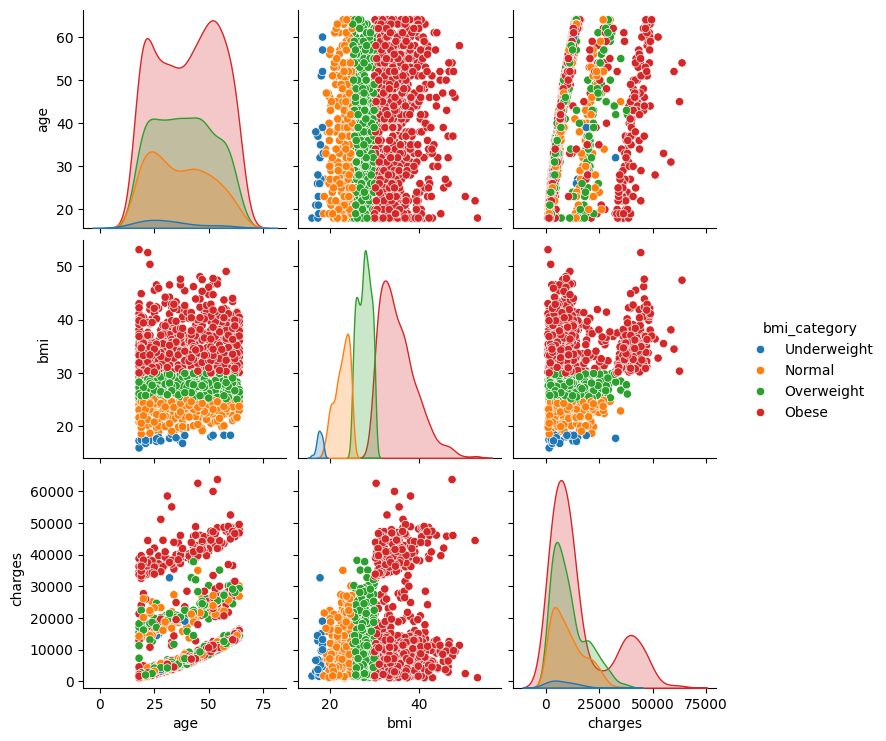

In [33]:
sns.pairplot(
    data,
    vars=["age", "bmi", "charges"],
    hue="bmi_category"
)

plt.show()

### EDA Note — Pair Plot by BMI Category

Colouring the pair plot by BMI category provides an additional view of the relationships between age, BMI and insurance charges.

The BMI categories are clearly separated in the BMI-related plots, as expected because the categories were derived directly from the continuous BMI variable.

The BMI versus charges plot shows that the Obese category contains a wider range of insurance charges and a greater number of high-charge observations. However, this exploratory pattern does not establish that BMI category is independently responsible for higher charges.

The age versus charges relationship continues to show several distinct patterns. The distribution of BMI categories within these patterns suggests that BMI may contribute to differences in charges, but other variables may also be important.

These observations support further investigation of smoking status and its interaction with BMI when examining insurance charges.

## 3.6 Sex vs Insurance Charges

Insurance charges are compared between males and females using a box plot.

The box plot allows comparison of the median, spread and potential extreme values of insurance charges between the two sex categories.

This visualisation provides an initial exploratory assessment of whether the charge distributions appear different. Statistical hypothesis testing will be performed later to determine whether any observed difference is statistically significant.

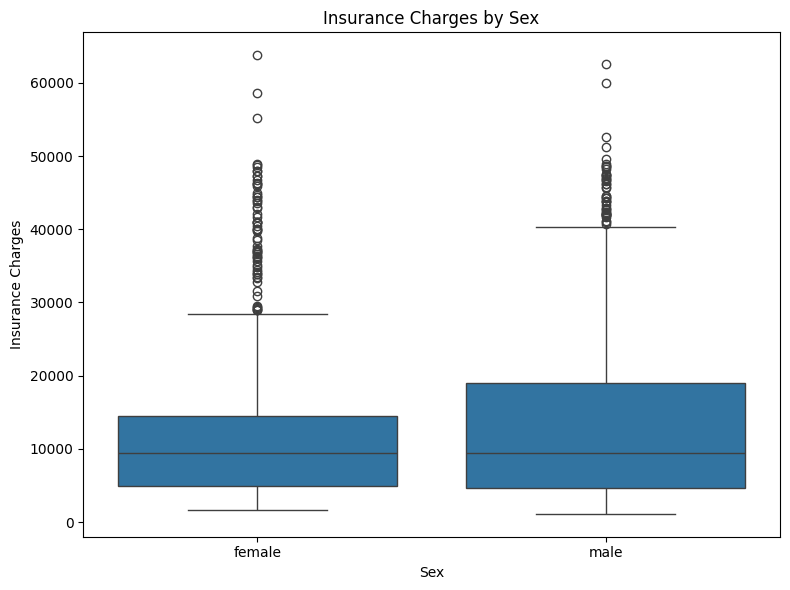

In [38]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=data,
    x="sex",
    y="charges"
)

plt.title("Insurance Charges by Sex")
plt.xlabel("Sex")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### EDA Note — Sex vs Insurance Charges

The box plot shows broadly similar median insurance charges for males and females.

The male group has a somewhat wider interquartile range and a higher upper whisker, while both groups contain numerous high-charge observations.

Overall, the visual difference between the two distributions appears relatively small compared with the much larger differences observed for smoking status and BMI-smoking groups.

This suggests that sex may have a weaker association with insurance charges than some of the other variables. Statistical hypothesis testing will be used later to determine whether any observed difference is statistically significant.

## 3.7 Number of Children vs Insurance Charges

Insurance charges are compared across different numbers of children using a box plot.

The visualisation allows comparison of the median, spread and potential extreme values of insurance charges for customers with different numbers of children.

This provides an exploratory assessment of whether insurance charges appear to vary according to the number of children. Statistical testing will be used later to determine whether any observed differences are statistically significant.

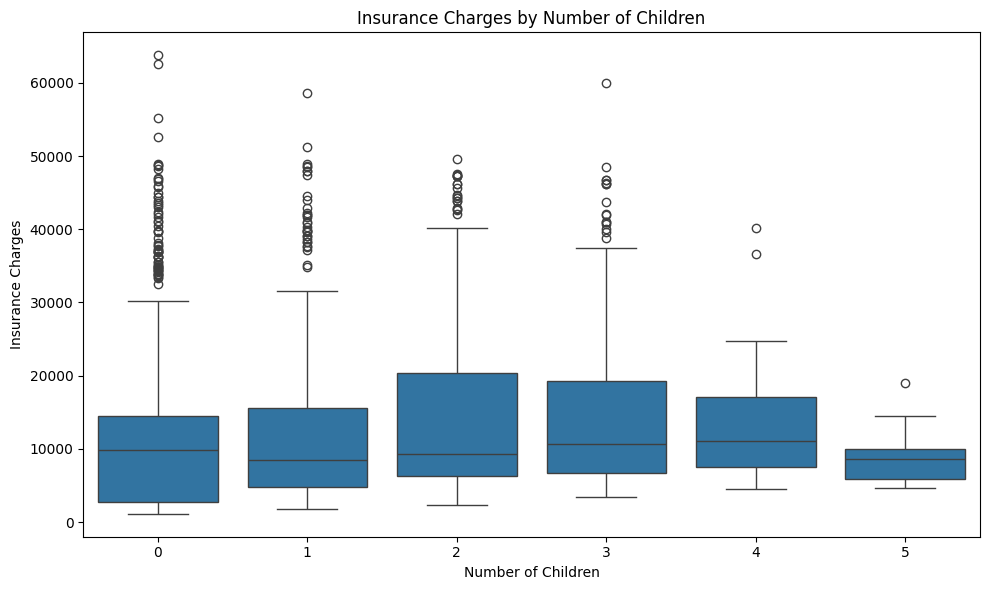

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="children",
    y="charges"
)

plt.title("Insurance Charges by Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### EDA Note — Number of Children vs Insurance Charges

The box plot shows some variation in insurance charges across the different numbers of children.

The median charges vary between groups, but there is no clear monotonic pattern in which charges consistently increase or decrease as the number of children increases.

The groups with zero to three children contain many high-charge observations, while the groups with four and five children contain fewer observations and therefore show greater uncertainty in their distributions.

Overall, the visualisation does not indicate a strong or simple relationship between the number of children and insurance charges. Statistical testing will be used later to determine whether the observed differences between groups are statistically significant.

## 3.8 Region vs Insurance Charges

Insurance charges are compared across the four geographic regions using a box plot.

The visualisation allows comparison of the median, spread and potential extreme values of insurance charges between regions.

This provides an exploratory assessment of whether insurance charges appear to differ geographically. Statistical testing will later determine whether any observed differences between regions are statistically significant.

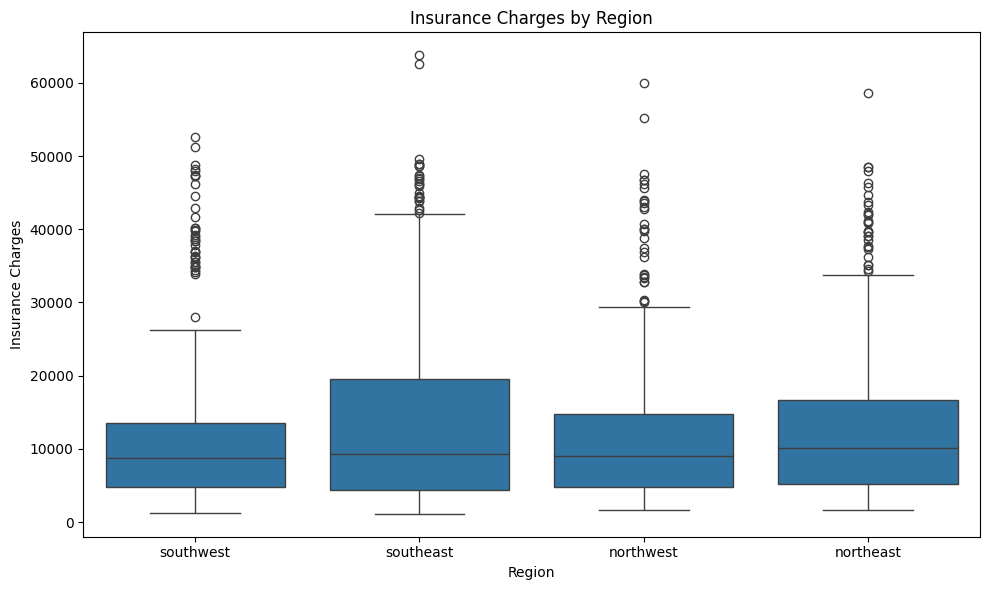

In [40]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="region",
    y="charges"
)

plt.title("Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.show()

### EDA Note — Region vs Insurance Charges

The box plot shows some differences in the distribution of insurance charges across the four geographic regions.

The median charges are broadly similar, although the Southeast and Northeast groups show somewhat wider distributions than the Southwest and Northwest groups.

All four regions contain numerous high-charge observations, with the Southeast showing particularly high upper-tail values.

Overall, the regional differences appear smaller than the differences observed for smoking status and the combined BMI-smoking groups. Statistical testing will be used later to determine whether the observed differences between regions are statistically significant.

### 3.5.1 Age vs Insurance Charges by Smoking Status and BMI

A scatter plot is used to examine the relationship between age and insurance
charges while considering smoking status and BMI simultaneously.

Smoking status is represented by colour, while BMI is represented by marker
size.

This multivariable visualisation allows the distribution of insurance charges
to be examined across different ages while considering two additional
customer characteristics.

The purpose of this plot is exploratory. It is used to identify patterns and
relationships that can be investigated further through statistical analysis.
It does not establish causation.

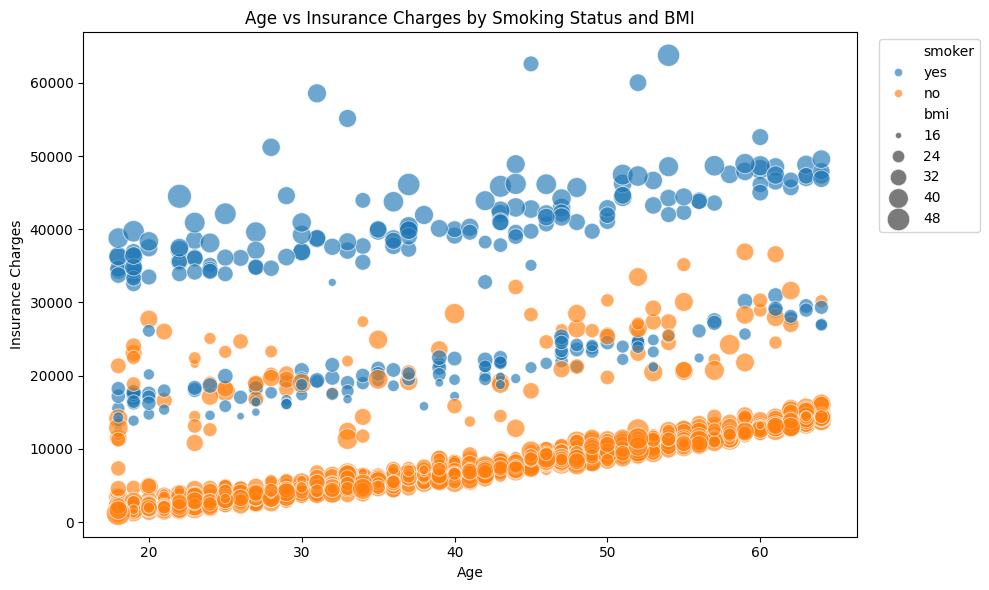

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x="age",
    y="charges",
    hue="smoker",
    size="bmi",
    sizes=(20, 300),
    alpha=0.65
)

plt.title("Age vs Insurance Charges by Smoking Status and BMI")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### EDA Note

The plot shows a clear separation in insurance charges between smokers and
non-smokers. Smokers generally occupy substantially higher charge levels than
non-smokers across the age range.

Among smokers, insurance charges generally increase with age, although the
relationship is not simply linear. Several distinct patterns or bands can be
observed in the distribution of charges.

BMI, represented by marker size, provides an additional dimension to the
visualisation. Larger markers occur across different charge levels, indicating
that BMI alone does not explain all of the variation observed in insurance
charges.

Overall, the visualisation suggests that smoking status is an important
variable when examining the relationship between age and insurance charges.
The observed patterns will be investigated further using statistical analysis.

### 3.5.2 BMI vs Insurance Charges by Smoking Status and Age

A scatter plot is used to examine the relationship between BMI and insurance
charges while considering smoking status and age simultaneously.

Smoking status is represented by colour, while age is represented by marker
size.

This provides a complementary view of the previous visualisation and helps
investigate whether the relationship between BMI and insurance charges differs
according to smoking status.

The visualisation is exploratory and does not establish causation.

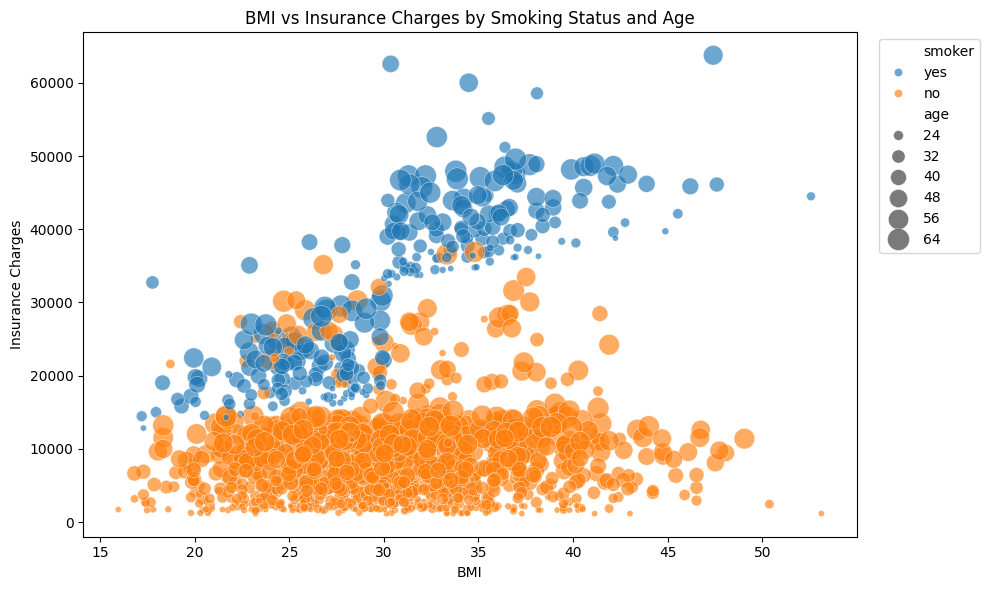

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x="bmi",
    y="charges",
    hue="smoker",
    size="age",
    sizes=(20, 250),
    alpha=0.65
)

plt.title("BMI vs Insurance Charges by Smoking Status and Age")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### EDA Note

The plot shows a substantial difference in insurance charge levels between
smokers and non-smokers.

Most non-smokers are concentrated at relatively lower charge values across a
wide range of BMI values. In contrast, smokers generally show substantially
higher charges, particularly at moderate to high BMI values.

The smoker group also shows greater variation in insurance charges.

Age, represented by marker size, provides additional context and suggests
that the observed variation in charges may involve several customer
characteristics rather than BMI alone.

Overall, the visualisation suggests that smoking status is an important factor
when examining the relationship between BMI and insurance charges. The
combined relationship between BMI and smoking status will be examined further
using the grouped analysis in the next section.

### 3.5.3 Insurance Charges by BMI and Smoking Status

To examine the combined relationship between BMI and smoking status, customers
are divided into four groups based on smoking status and whether BMI is below
or above 30:

- Non-smoker, BMI < 30
- Non-smoker, BMI ≥ 30
- Smoker, BMI < 30
- Smoker, BMI ≥ 30

A box plot is used to compare the distribution of insurance charges across
these four groups.

This provides a direct comparison of the central tendency, spread and
potential extreme values of insurance charges for different combinations of
BMI and smoking status.

The analysis is exploratory and describes associations within the dataset; it
does not establish causation.

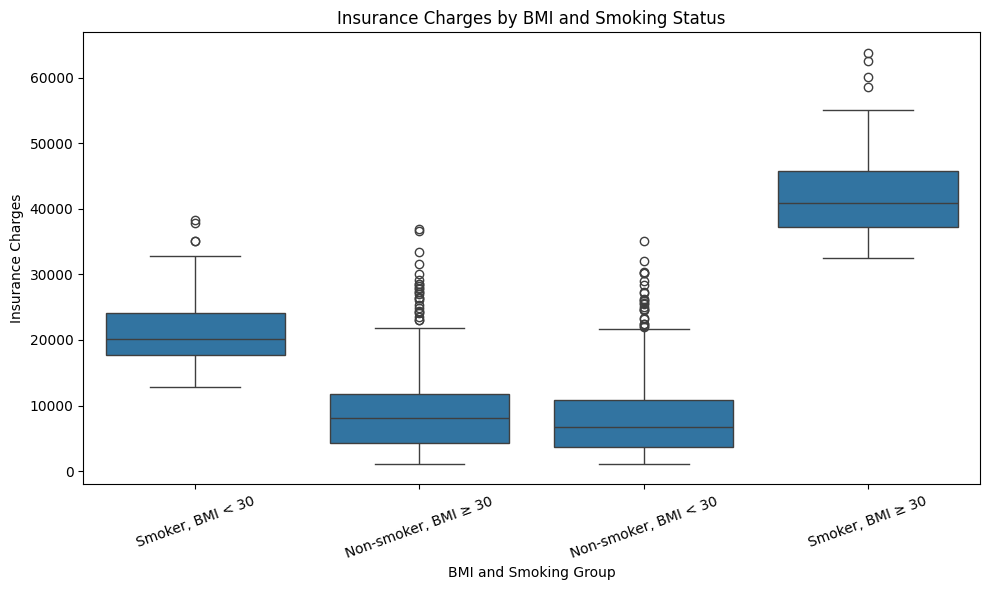

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="bmi_smoker_group",
    y="charges"
)

plt.title("Insurance Charges by BMI and Smoking Status")
plt.xlabel("BMI and Smoking Group")
plt.ylabel("Insurance Charges")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### EDA Note

The box plot shows substantial differences in insurance charge distributions
between the four BMI and smoking groups.

The Smoker, BMI ≥ 30 group has the highest median insurance charges and the
highest overall distribution of charges.

The Smoker, BMI < 30 group also has substantially higher median charges than
both non-smoking groups.

Among non-smokers, the median charges are relatively similar between the two
BMI groups, although the BMI ≥ 30 group shows a somewhat wider distribution.

Overall, smoking status appears to be associated with a much larger difference
in insurance charges than the BMI threshold considered in this analysis.
However, the combined pattern suggests that BMI may provide additional
information within smoking groups.

These observations provide a strong basis for the statistical hypothesis
testing stage, where the differences between the groups can be formally
investigated.

## 3.9 Distribution of Insurance Charges by BMI and Smoking Group

The distribution of insurance charges is examined separately for the four
BMI and smoking groups.

Histograms with density curves are used to compare the location, spread and
shape of the charge distributions between the groups.

This visualisation provides a complementary view of the box plot and helps
identify whether the groups occupy different ranges of insurance charges.

The analysis is exploratory and describes associations within the dataset; it
does not establish causation.

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.show()

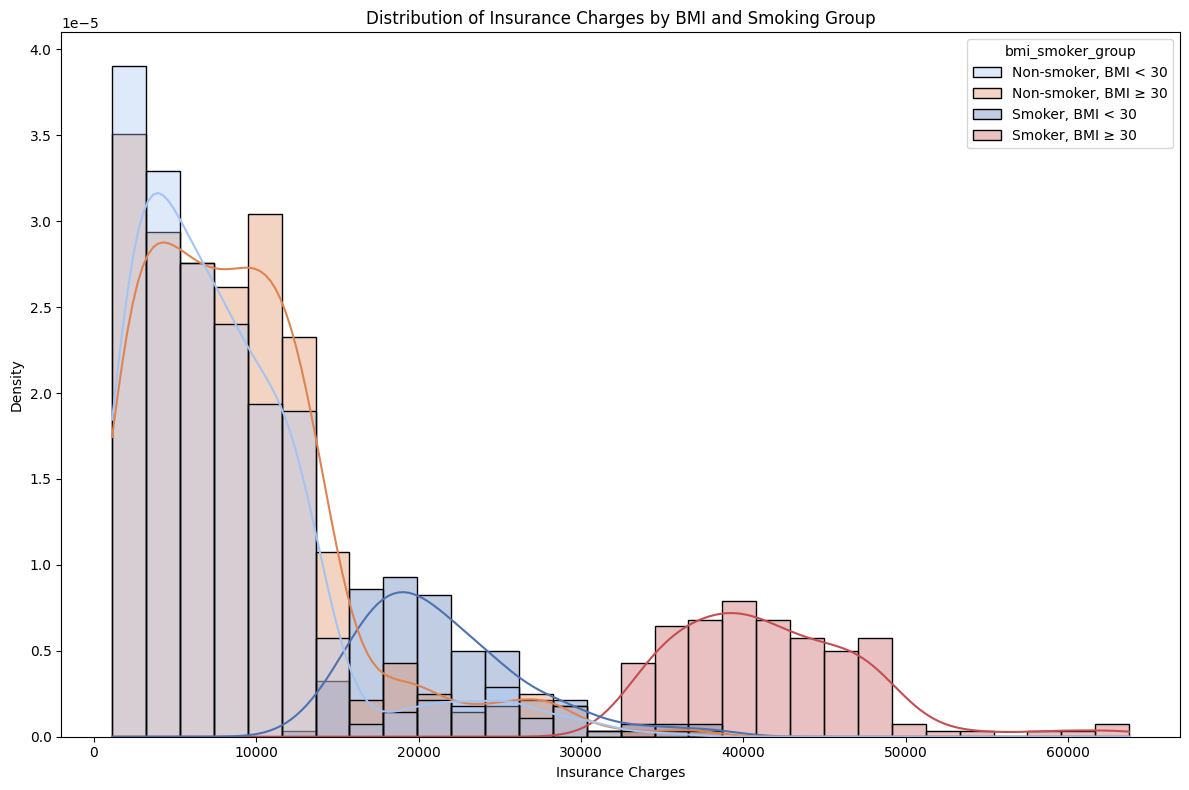

In [54]:
hue_order = [
    "Non-smoker, BMI < 30",
    "Non-smoker, BMI ≥ 30",
    "Smoker, BMI < 30",
    "Smoker, BMI ≥ 30"
]

group_palette = [
    "#A3C4F3",
    "#DD8452",
    "#4C72B0",
    "#C44E52"
]

plt.figure(figsize=(12, 8))

sns.histplot(
    data=data,
    x="charges",
    hue="bmi_smoker_group",
    hue_order=hue_order,
    palette=group_palette,
    bins=30,
    kde=True,
    stat="density",
    alpha=0.35
)

plt.title("Distribution of Insurance Charges by BMI and Smoking Group")
plt.xlabel("Insurance Charges")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

### EDA Note — Distribution of Insurance Charges by BMI and Smoking Group

The distributions show a clear separation in insurance charges between the four
BMI and smoking groups.

The two non-smoking groups are concentrated mainly at lower insurance charge
values, although the Non-smoker, BMI ≥ 30 group extends further into the
higher-charge range.

The Smoker, BMI < 30 group is shifted towards substantially higher charges than
the non-smoking groups, with most observations occurring at approximately
£13,000 to £30,000 and some extending above £30,000.

The Smoker, BMI ≥ 30 group has the most distinct distribution. Its charges are
concentrated mainly at substantially higher values, with many observations
between approximately £30,000 and £50,000 and some extending beyond £60,000.

Overall, the distributions indicate a strong association between smoking
status and insurance charges. The comparison also suggests that BMI provides
additional information when considered together with smoking status.

These patterns are exploratory and do not establish that smoking or BMI causes
higher insurance charges. The observed differences will be investigated
formally during the statistical hypothesis-testing stage.

## 3.11 EDA Findings

The exploratory data analysis identified several important patterns in the
healthcare insurance dataset.

### Insurance Charges

The distribution of insurance charges is strongly right-skewed, with most
observations concentrated at relatively lower charge values and a smaller
number of observations extending to substantially higher charges.

Potential high-value observations were retained because they may represent
genuine insurance costs rather than data-entry errors.

### Smoking Status

Smoking status shows the clearest visual difference in insurance charges.
Smokers generally have substantially higher charges than non-smokers across
the observed age and BMI ranges.

### Age

Insurance charges generally increase with age, particularly among smokers.
The relationship is not completely linear and several distinct patterns are
visible in the age versus charges visualisation.

### BMI

BMI shows a weaker and less straightforward relationship with insurance
charges when considered independently. The relationship becomes more
informative when BMI is considered together with smoking status.

### BMI and Smoking

The combined BMI and smoking analysis shows substantial differences between
the four groups.

The Smoker, BMI ≥ 30 group has the highest median insurance charges and the
highest overall distribution of charges. The non-smoking groups have
substantially lower charge distributions.

This suggests that considering BMI and smoking status together provides more
information about insurance charges than considering BMI alone.

### Sex

The male and female charge distributions have similar median values, although
the male group shows a somewhat wider distribution.

The visual difference appears smaller than the differences observed for
smoking status and the combined BMI-smoking groups.

### Number of Children

Insurance charges vary across the different numbers of children, but there is
no clear monotonic pattern.

The groups with four and five children contain fewer observations, so
comparisons involving these groups should be interpreted cautiously.

### Region

Some differences are visible between the four regions, particularly in the
spread and upper tail of the distributions. However, these differences appear
smaller than those associated with smoking status.

### Overall EDA Conclusion

Overall, smoking status appears to be the strongest visual factor associated
with insurance charges in this dataset.

Age also shows an important relationship with charges, while BMI provides
additional information when considered together with smoking status.

The exploratory findings support the research questions and hypotheses defined
for the project. These observations will be formally investigated using
statistical hypothesis testing in the next stage.

The EDA findings describe associations within the dataset and should not be
interpreted as evidence of causation.